# Đánh giá năm tác tử Caro 11×11

Câu hỏi nghiên cứu là MCTS và Alpha-Beta đạt score và chi phí thế nào khi cùng giới hạn 2 giây/nước; CNN học từ tactical-v1 thi đấu ra sao trước các tác tử tìm kiếm và luật. Notebook tổng hợp trực tiếp log, giữ riêng hai chế độ ngân sách.

Các lượt pilot dùng để kiểm tra tích hợp. Chỉ các lượt chính thức đủ 100 ván/cặp mới phục vụ kết luận giải đấu. Cấu hình mã nguồn, luật, seed và checkpoint được lưu trong từng thư mục kết quả.

In [1]:
from pathlib import Path
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if Path.cwd().name == 'notebooks':
    os.chdir(Path.cwd().parent)
from evaluation.analyze import summarize

runs = {}
for mode in ('fixed', 'time'):
    official = Path(f'results/match_logs/official-{mode}')
    pilot = Path(f'results/match_logs/pilot-{mode}')
    runs[mode] = official if (official / 'config.json').is_file() else pilot
    if not (runs[mode] / 'config.json').is_file():
        raise FileNotFoundError(f'Hãy chạy giải {mode} theo docs/Chay-giai-dau-va-demo.md trước')
    print('Đọc log từ', runs[mode])
reports = {mode: summarize(directory) for mode, directory in runs.items()}
for mode, report in reports.items():
    print(f"{mode}: {report['completed_games']}/{report['scheduled_games']} ván, {report['config']['games_per_pair']} ván/cặp")
    if report['config']['games_per_pair'] < 100 or not report['complete']:
        print('Lượt pilot hoặc chưa đủ ván. Phạm vi kết luận là kiểm chứng tích hợp.')

Đọc log từ results\match_logs\pilot-fixed
Đọc log từ results\match_logs\pilot-time
fixed: 20/20 ván, 2 ván/cặp
Lượt pilot hoặc chưa đủ ván. Phạm vi kết luận là kiểm chứng tích hợp.
time: 20/20 ván, 2 ván/cặp
Lượt pilot hoặc chưa đủ ván. Phạm vi kết luận là kiểm chứng tích hợp.


## Bảng kết quả và độ trễ

Score tính bằng (thắng + 0,5 × hòa) / tổng ván. Ván xử thua được tính vào kết quả và liệt kê riêng. Mean và p95 lấy thời gian yêu cầu/đáp ứng của các nước hợp lệ; timeout được tổng hợp bằng số ván xử thua. Thống kê số nút và mô phỏng giữ nguyên cách đếm của từng thuật toán.

,chế độ,agent,thắng,hòa,thua,score,mean_ms,p95_ms,xử thua,nút,mô phỏng
0,fixed,random,0,0,8,0.000,0.390285,0.506250,0,0,0
1,fixed,rule,6,0,2,0.750,38.166770,126.932165,0,91990,0
2,fixed,minimax,7,0,1,0.875,64.387598,253.986500,0,62166,0
3,fixed,mcts,2,0,6,0.250,539.194812,924.930285,0,73595,74000
4,fixed,neural,5,0,3,0.625,1.710740,2.545925,0,0,0
5,time,random,0,0,8,0.000,0.425580,0.555120,0,0,0
6,time,rule,5,0,3,0.625,42.692582,148.120950,0,95841,0
7,time,minimax,8,0,0,1.000,1586.991658,1900.540100,0,1350316,0
8,time,mcts,3,0,5,0.375,1900.684358,1900.752620,0,197265,238025
9,time,neural,4,0,4,0.500,1.811140,3.222390,0,0,0


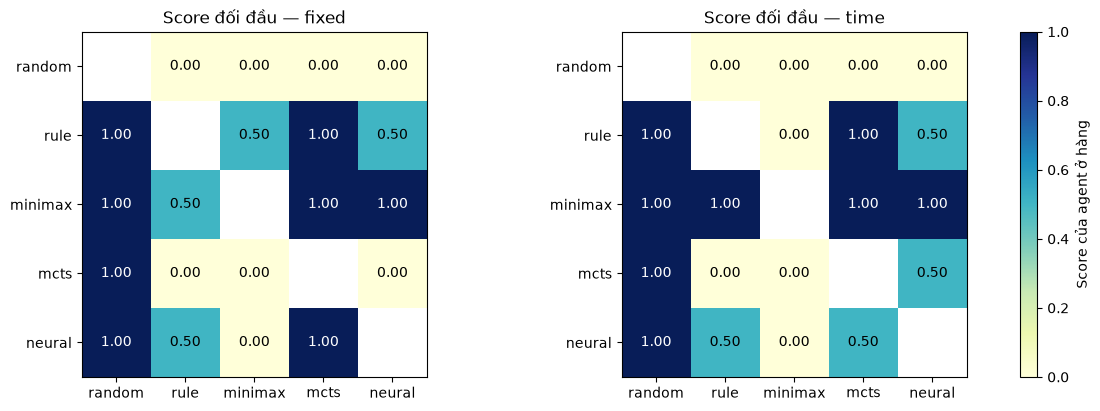

In [2]:
rows = []
for mode, report in reports.items():
    for agent, stats in report['agents'].items():
        rows.append({'chế độ': mode, 'agent': agent, 'thắng': stats['wins'], 'hòa': stats['draws'],
                     'thua': stats['losses'], 'score': stats['score'],
                     'mean_ms': (stats['latency']['mean_s'] or 0)*1000,
                     'p95_ms': (stats['latency']['p95_s'] or 0)*1000,
                     'xử thua': sum(stats['forfeits'].values()),
                     'nút': stats['nodes_visited'], 'mô phỏng': stats['simulations']})
table = pd.DataFrame(rows)
display(table)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
for ax, (mode, report) in zip(axes, reports.items()):
    names = report['config']['agents']
    matrix = np.full((len(names), len(names)), np.nan)
    for pair in report['pairs'].values():
        i, j = names.index(pair['agent']), names.index(pair['opponent'])
        matrix[i, j], matrix[j, i] = pair['score'], 1-pair['score']
    image = ax.imshow(matrix, vmin=0, vmax=1, cmap='YlGnBu')
    ax.set(xticks=range(len(names)), yticks=range(len(names)), xticklabels=names, yticklabels=names,
           title=f'Score đối đầu — {mode}')
    for i in range(len(names)):
        for j in range(len(names)):
            if np.isfinite(matrix[i,j]):
                ax.text(j, i, f'{matrix[i,j]:.2f}', ha='center', va='center', color='white' if matrix[i,j] > .6 else 'black')
fig.colorbar(image, ax=axes, label='Score của agent ở hàng')
plt.show()

## Khoảng tin cậy và lượt đi trước

Bootstrap 2.000 lần theo cặp ván cùng seed đổi X/O, seed bootstrap là 42. Chỉ tính khoảng khi có ít nhất hai cặp hoàn chỉnh. Hai tác tử tất định có thể lặp lại cùng quỹ đạo khi xuất phát bàn trống, nên nhiều seed chưa tạo thêm thế cờ khác nhau cho cặp đó. Báo riêng score khi cầm X và O để quan sát lợi thế đi trước.

In [3]:
for mode, report in reports.items():
    print('Chế độ', mode)
    display(pd.DataFrame(report['pairs'].values())[['agent', 'opponent', 'total', 'score', 'score_ci95_paired_bootstrap']])
    display(pd.DataFrame([{'agent': name, 'bên': side, 'ván': stats['total'], 'score': stats['score']}
                          for name, agent in report['agents'].items() for side, stats in agent['by_side'].items()]))

Chế độ fixed


,agent,opponent,total,score,score_ci95_paired_bootstrap
0,random,rule,2,0.0,None
1,minimax,random,2,1.0,None
2,mcts,random,2,1.0,None
3,neural,random,2,1.0,None
4,minimax,rule,2,0.5,None
5,mcts,rule,2,0.0,None
6,neural,rule,2,0.5,None
7,mcts,minimax,2,0.0,None
8,minimax,neural,2,1.0,None
9,mcts,neural,2,0.0,None


,agent,bên,ván,score
0,random,X,4,0.00
1,random,O,4,0.00
2,rule,X,4,1.00
3,rule,O,4,0.50
4,minimax,X,4,1.00
5,minimax,O,4,0.75
6,mcts,X,4,0.25
7,mcts,O,4,0.25
8,neural,X,4,0.75
9,neural,O,4,0.50


Chế độ time


,agent,opponent,total,score,score_ci95_paired_bootstrap
0,random,rule,2,0.0,None
1,minimax,random,2,1.0,None
2,mcts,random,2,1.0,None
3,neural,random,2,1.0,None
4,minimax,rule,2,1.0,None
5,mcts,rule,2,0.0,None
6,neural,rule,2,0.5,None
7,mcts,minimax,2,0.0,None
8,minimax,neural,2,1.0,None
9,mcts,neural,2,0.5,None


,agent,bên,ván,score
0,random,X,4,0.00
1,random,O,4,0.00
2,rule,X,4,0.75
3,rule,O,4,0.50
4,minimax,X,4,1.00
5,minimax,O,4,1.00
6,mcts,X,4,0.25
7,mcts,O,4,0.50
8,neural,X,4,0.50
9,neural,O,4,0.50


## Hai thí nghiệm đối chứng

Alpha-Beta bật/tắt được đối chiếu trên cùng sáu vị trí ở độ sâu 1 và 2, giữ nguyên lượng giá và thứ tự xét. Đối chứng pattern giữ các luật thắng/chặn và phương pháp phá hòa; bốn vị trí chiến thuật có đáp án đặt trước. Hai vị trí mở đầu/trung cuộc chỉ đo thay đổi nước đi và thời gian.

In [4]:
ablation = json.loads(Path('results/statistics/ablations.json').read_text(encoding='utf-8'))
rows = []
for item in ablation['results']:
    for result in item['runs']:
        rows.append({'vị trí': item['position'], 'thí nghiệm': item['experiment'],
                     'độ sâu': item.get('depth'), 'cắt tỉa': result.get('alpha_beta'),
                     'pattern': result.get('patterns'), 'nước': result['action'],
                     'đúng chiến thuật': result.get('tactical_correct'),
                     'nút': result['stats']['nodes_visited'], 'giây': result['stats']['thinking_time']})
display(pd.DataFrame(rows))

,vị trí,thí nghiệm,độ sâu,cắt tỉa,pattern,nước,đúng chiến thuật,nút,giây
0,mo_dau,alpha_beta,1.0,False,None,"[4, 4]",None,29,0.001991
1,mo_dau,alpha_beta,1.0,True,None,"[4, 4]",None,29,0.001582
2,mo_dau,alpha_beta,2.0,False,None,"[4, 6]",None,1079,0.050508
3,mo_dau,alpha_beta,2.0,True,None,"[4, 6]",None,234,0.013368
4,mo_dau,patterns,NaN,None,False,"[4, 5]",None,266,0.001412
5,mo_dau,patterns,NaN,None,True,"[4, 5]",None,1926,0.054996
6,trung_cuoc,alpha_beta,1.0,False,None,"[6, 4]",None,41,0.002303
7,trung_cuoc,alpha_beta,1.0,True,None,"[6, 4]",None,41,0.002174
8,trung_cuoc,alpha_beta,2.0,False,None,"[6, 7]",None,1965,0.088124
9,trung_cuoc,alpha_beta,2.0,True,None,"[6, 7]",None,198,0.014052


## Đọc ván điển hình và giới hạn

Dùng log từng nước để phát lại ván thua, đối chiếu ô thắng/chặn bị bỏ lỡ và thời điểm phát sinh timeout. Cấu hình của các tác tử được đóng băng trước giải chính thức. Mô hình CNN học từ tactical-v1; top-1 trên dữ liệu có nhãn được báo trong notebook Neural Network. Kết luận sức chơi dựa vào giải đấu hoàn chỉnh. Các phép đo thời gian phụ thuộc phần cứng và tải máy.